# DSA80003: Data Mining
**Group:** 4 

**Members:**

**Submission Date:** 26th November, 2026

### Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotnine
from pathlib import Path
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

## Data Collection

In [4]:
# 1. Find the dataset folder (works on Kaggle, on our laptops, or downloads it as a last resort)
import os
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

KAGGLE_INPUT = Path("/kaggle/input/datasets/abrarmahirsahil/human-activity-recognition-using-smartphones-zip")
ON_KAGGLE = Path("/kaggle").exists()

# Kaggle's input folder is READ-ONLY, so anything we unzip must go to /kaggle/working
WORK_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".")
dataset_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# Places to search, in order: Kaggle dataset, our unzip folder, the notebook's own folder
SEARCH_ROOTS = [KAGGLE_INPUT, Path("/kaggle/input"), WORK_DIR, Path(".")]


def find_data_dir():
    """Return the first folder that contains features.txt AND the train/ folder."""
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for f in sorted(root.rglob("features.txt")):
            if "__MACOSX" in f.parts:           # skip the hidden Mac copies inside the zip
                continue
            if (f.parent / "train" / "X_train.txt").exists():
                return f.parent
    return None


def unzip_all_layers():
    """The UCI zip contains ANOTHER zip ('UCI HAR Dataset.zip'). Unzip every layer into WORK_DIR."""
    done = set()
    while True:
        zips = {z.resolve(): z for root in SEARCH_ROOTS if root.exists()
                for z in root.rglob("*.zip")
                if "__MACOSX" not in z.parts and z.resolve() not in done}   # dict = no duplicates
        if not zips:
            return
        for key, z in zips.items():
            done.add(key)
            print("Unzipping:", z)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(WORK_DIR)


data_dir = find_data_dir()

# 2. Not found? Unzip any zip we have (e.g. the Kaggle upload or the local download)
if data_dir is None:
    unzip_all_layers()
    data_dir = find_data_dir()

# 3. Still not found? Try to download from UCI (internet must be ON in Kaggle settings)
if data_dir is None:
    print("Dataset not found locally. Attempting to download the UCI HAR dataset...")
    try:
        zip_path = WORK_DIR / "uci_har.zip"
        urllib.request.urlretrieve(dataset_url, zip_path)
        unzip_all_layers()
        data_dir = find_data_dir()
    except Exception as e:
        raise FileNotFoundError(
            f"Could not automatically download the dataset: {e}\n\n"
            f"Please download 'Human Activity Recognition Using Smartphones' manually from:\n"
            f"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n"
            f"On Kaggle, add it with 'Add Input'. On a laptop, extract it next to this notebook."
        )

if data_dir is None:
    raise FileNotFoundError("features.txt was not found anywhere. Check the dataset folder structure.")

print("Running on Kaggle:", ON_KAGGLE)
print("Using dataset folder:", data_dir)

# 4. Load feature names
features_df = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

print(f"Successfully loaded {len(feature_names)} unique feature names.")

Running on Kaggle: True
Using dataset folder: /kaggle/input/datasets/abrarmahirsahil/human-activity-recognition-using-smartphones-zip/UCI HAR Dataset/UCI HAR Dataset
Successfully loaded 561 unique feature names.


### Split Dataset

In [5]:
import pandas as pd
from pathlib import Path

# 1. Define root path and load features ONCE (since they are shared between train and test)
# FIX (Abrar): reuse data_dir found in the cell above (do not reset it here)

features_df = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)


# 2. Create a reusable function for loading any split ('train' or 'test')
def load_har_split(split_name: str, data_dir: Path, feature_names: list) -> pd.DataFrame:
    """
    Loads and combines subject IDs, activity labels, and features 
    for a given dataset split ('train' or 'test').
    """
    split_dir = data_dir / split_name
    
    # Load individual components dynamically based on the split name
    X = pd.read_csv(split_dir / f"X_{split_name}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(split_dir / f"y_{split_name}.txt", sep=r"\s+", header=None, names=["activity_id"])
    subject = pd.read_csv(split_dir / f"subject_{split_name}.txt", sep=r"\s+", header=None, names=["subject_id"])
    
    # Combine everything into a single DataFrame
    df = pd.concat([subject, y, X], axis=1)
    
    return df


# 3. Load both train and test sets easily using the function
train_df = load_har_split("train", data_dir, feature_names)
test_df = load_har_split("test", data_dir, feature_names)

# FIX (Abrar): the scaling cell below needs a readable activity name column
activity_map = {1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS",
                4: "SITTING", 5: "STANDING", 6: "LAYING"}
def add_activity_name(df):
    names = df["activity_id"].map(activity_map).rename("activity_name")
    return pd.concat([df.iloc[:, :2], names, df.iloc[:, 2:]], axis=1)
train_df = add_activity_name(train_df)
test_df = add_activity_name(test_df)

# Preview results
print(f"Train shape: {train_df.shape}")  # Should show (7352, 564)
print(f"Test shape:  {test_df.shape}")   # Should show (2947, 564)

Train shape: (7352, 564)
Test shape:  (2947, 564)


## Dataset Preprocessing

### Missingness Analysis

In [6]:
# 1. Check for missing values
train_missing = train_df.isnull().sum().sum()
test_missing = test_df.isnull().sum().sum()
print(f"Missing values -> Train: {train_missing} | Test: {test_missing}")

# 2. Check for duplicate rows
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows -> Train: {train_dups} | Test: {test_dups}")

# 3. Inspect shapes and target distributions
print(f"\nTrain shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Missing values -> Train: 0 | Test: 0
Duplicate rows -> Train: 0 | Test: 0

Train shape: (7352, 564)
Test shape:  (2947, 564)


Retrieve Feature Columns

### Apply standard scaling

Retain both the scaled and unscaled version

In [7]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate features from metadata
meta_cols = ["subject_id", "activity_name", "activity_id"]

X_train = train_df.drop(columns=meta_cols)
X_test = test_df.drop(columns=meta_cols)   # FIX (Abrar): X_test was never created

# Preserve metadata separately
meta_train = train_df[meta_cols].copy()
meta_test = test_df[meta_cols].copy()

# Initialize the scaler
scaler = StandardScaler()

# Fit on the training features and transform both train and test sets
# (Fitting strictly on train to prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve original 561 feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print(f"Scaled Training Shape: {X_train_scaled_df.shape}")
print(f"Scaled Testing Shape:  {X_test_scaled_df.shape}")

Scaled Training Shape: (7352, 561)
Scaled Testing Shape:  (2947, 561)


### Items to use for EDA

In [8]:
# FIX (Abrar): the last line had a syntax error
print("Unscaled dataset:", X_train.shape)
print("Scaled dataset:  ", X_train_scaled.shape)
print("Metadata (subject_id, activity_name, activity_id):", meta_train.shape)

Unscaled dataset: (7352, 561)
Scaled dataset:   (7352, 561)
Metadata (subject_id, activity_name, activity_id): (7352, 3)


### Exploratory Data Analysis

Task 1 — Data quality and feature characteristics
Objective: Understand the quality and structure of the sensor measurements.

**Member**: Atharva

What needs to be done:

1. Check missing values, duplicates, constant features and extreme values.
2. Examine feature distributions and variance.
3. Identify highly correlated and redundant features.
4. Group features by their physical meaning: acceleration, gyroscope, gravity, jerk, time-domain and frequency-domain.
5. Examine how standardisation and duplicate-feature removal change feature distributions and relative weighting.

Expected output: A summary of data quality, feature redundancy and recommended preprocessing decisions.

In [7]:
# Code for EDA 1

Task 2 — Natural structure and movement relationships

Objective: Investigate whether the sensor data suggest meaningful movement groups and relationships.

**Member**: Abrar

What needs to be done:
1. Explore PCA projections of the sensor measurements.
2. Examine whether observations form distinct regions, overlapping distributions or continuous patterns.
3. Look for broad movement families and possible finer subdivisions.
4. Compare the apparent structure against known activity labels, using labels only for interpretation.
5. Investigate whether some activities occupy overlapping or nested regions of sensor space.
Expected output: Evidence describing the apparent organisation of movement and hypotheses about shared movement patterns.

At this stage, visual groupings are exploratory evidence, not validated clusters.


### Task 2 — Natural structure and movement relationships (Abrar)

**The question in plain words:** if we hide the activity labels and simply *look* at the sensor data, does it fall into natural groups? Are those groups sharp and separate, do they overlap, or do they blend smoothly into each other?

**What data we use**
- The **scaled training windows** from the preprocessing step (`X_train_scaled_df`): 7,352 windows × 561 features.
- One row = one **2.56-second window** of one person doing one activity. This is our unit of analysis.
- We use only the training set so that the test set stays untouched for later steps, the same choice the team made when fitting the scaler.

**The one rule of this section:** PCA never sees `activity_name` or `subject_id`. We first look at the shapes *without* labels. Only afterwards do we colour the points by the true labels, to *interpret* what we found.

**Plan**
1. Run PCA and see how much information the first few components hold.
2. Find out what each of the first components means physically.
3. Look at the data **without labels**: is there any structure at all?
4. Add the labels and compare.
5. Look for broad movement families, then finer groups inside each family.
6. Measure which activities overlap, and which sit inside one another.
7. Check the picture with a second, non-linear method (t-SNE).
8. Summarise the evidence and the hypotheses we will test with real clustering in RQ1.

*Reminder from the brief: everything here is exploratory evidence, not validated clusters.*

In [8]:
# ---- Setup for Task 2 -------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform

RNG = 42                                   # fixed seed so every result can be reproduced
X2 = X_train_scaled_df.values               # 7,352 x 561, already standardised
acts = meta_train["activity_name"].to_numpy(dtype=object)    # used ONLY for interpretation
subj = meta_train["subject_id"].to_numpy()                   # used ONLY for interpretation

# Fixed activity order and colours (dynamic first, then static), checked for colour-blind safety
ACT_ORDER = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
SHORT = {"WALKING": "Walk", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sit", "STANDING": "Stand", "LAYING": "Lay"}
COLORS = dict(zip(ACT_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
DYNAMIC = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
print("Windows:", X2.shape[0], "| Features:", X2.shape[1])

Windows: 7352 | Features: 561


#### 2.1 How much information do the first components hold?

**What PCA does:** it rotates the data to find new axes (called *principal components*, PC1, PC2, ...). PC1 is the direction where the data spreads the most, PC2 the next most, and so on. If a few PCs hold most of the spread, the 561 features are really telling a much smaller story.

Share of information in each of the first 5 PCs: [50.8  6.6  2.8  2.5  1.9] %
  50% of the information needs   1 PCs (out of 561)
  80% of the information needs  26 PCs (out of 561)
  90% of the information needs  63 PCs (out of 561)
  95% of the information needs 102 PCs (out of 561)


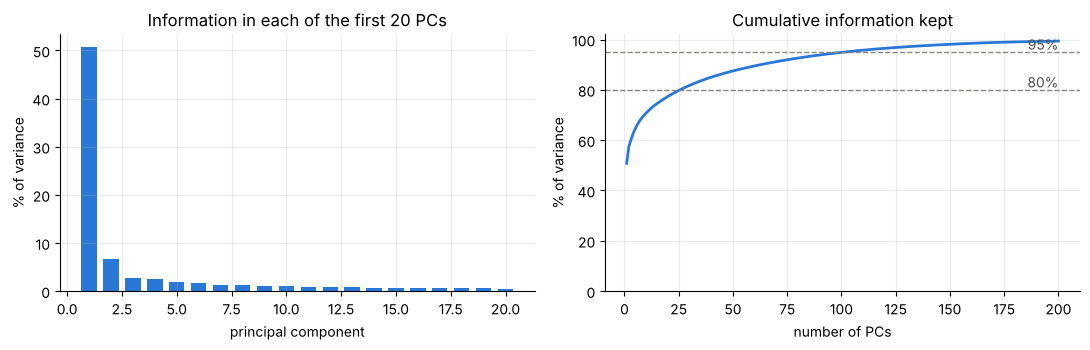

In [9]:
pca = PCA(random_state=RNG).fit(X2)
Z = pca.transform(X2)                       # every window, expressed in PC coordinates
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

print("Share of information in each of the first 5 PCs:", np.round(evr[:5] * 100, 1), "%")
for target in [0.50, 0.80, 0.90, 0.95]:
    print(f"  {target:.0%} of the information needs {np.argmax(cum >= target) + 1:>3} PCs (out of 561)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(range(1, 21), evr[:20] * 100, color="#2a78d6", width=0.7)
ax[0].set(title="Information in each of the first 20 PCs", xlabel="principal component", ylabel="% of variance")
ax[1].plot(range(1, 201), cum[:200] * 100, color="#2a78d6", lw=2)
for t, c in [(80, "#898781"), (95, "#898781")]:
    ax[1].axhline(t, ls="--", lw=1, color=c)
    ax[1].text(200, t + 1, f"{t}%", ha="right", color="#52514e")
ax[1].set(title="Cumulative information kept", xlabel="number of PCs", ylabel="% of variance", ylim=(0, 102))
plt.tight_layout(); plt.show()

**What this shows**
- **PC1 alone holds about half (≈51%) of all the variation.** That is unusually large. It means one single "theme" dominates the whole dataset.
- After PC1, each extra component adds only a little (PC2 ≈ 7%, PC3 ≈ 3%).
- About **100 components keep 95%** of the information. So the 561 features contain a lot of repetition, which matches the redundancy that Task 1 looks at.

**Why this matters for later:** a 2-D picture (PC1 + PC2) shows only about 57% of the information. So what looks like overlap in a 2-D plot might **not** be real overlap in the full space. We check exactly this in Section 2.6.

#### 2.2 What does each component mean physically?

A PC is a weighted mix of the original features. The features with the biggest weights (called *loadings*) tell us what the PC "is about".

In [10]:
def top_loadings(k, n=8):
    w = pd.Series(pca.components_[k], index=X_train_scaled_df.columns)
    return w.reindex(w.abs().sort_values(ascending=False).index)[:n].round(3)

for k in range(3):
    print(f"\n--- PC{k+1} ({evr[k]*100:.1f}% of variance): strongest features ---")
    print(top_loadings(k).to_string())


--- PC1 (50.8% of variance): strongest features ---
fBodyAcc-sma()                0.059
fBodyAccJerk-sma()            0.059
tBodyAccJerk-sma()            0.059
fBodyGyro-sma()               0.059
tBodyAccJerkMag-mean()        0.058
tBodyAccJerkMag-sma()         0.058
fBodyBodyAccJerkMag-mean()    0.058
fBodyBodyAccJerkMag-sma()     0.058

--- PC2 (6.6% of variance): strongest features ---
fBodyAcc-meanFreq()-Z        0.122
tBodyGyroMag-arCoeff()1      0.120
tBodyAccMag-arCoeff()1       0.118
tGravityAccMag-arCoeff()1    0.118
fBodyAccMag-meanFreq()       0.118
tGravityAcc-arCoeff()-Z,1    0.118
tGravityAcc-arCoeff()-Z,2   -0.117
tGravityAcc-arCoeff()-Z,3    0.115

--- PC3 (2.8% of variance): strongest features ---
tGravityAcc-energy()-X       0.110
tGravityAcc-arCoeff()-X,1    0.110
tGravityAcc-entropy()-Y     -0.110
tGravityAcc-energy()-Z      -0.109
tGravityAcc-min()-X          0.108
angle(X,gravityMean)        -0.108
tGravityAcc-std()-X         -0.104
tGravityAcc-mean()-X         0

**How to read the feature names:** `t` = time domain, `f` = frequency domain, `Body` = movement of the body, `Gravity` = direction of gravity (phone orientation), `Jerk` = how suddenly the movement changes, `Mag` = overall size, `sma` / `energy` / `mean` = how much movement in total.

**Interpretation**
- **PC1 = movement intensity.** Its top features are all "how much the body moves" (`BodyAcc-sma`, `BodyAccJerk`, `BodyGyro`). A high PC1 means a lot of motion, and a low PC1 means the person is still.
- **PC2 = rhythm and frequency of the signal.** It is driven by `arCoeff` (how a signal follows its own recent past) and `meanFreq` (the typical frequency). It describes *how* a movement repeats, not how strong it is.
- **PC3 = body orientation.** It is driven by `tGravityAcc` and `angle(X, gravityMean)`, which describe which way gravity points relative to the phone. That is posture: upright or lying down.

So the three main directions of the data have clear physical meanings: **intensity, rhythm and posture**.

#### 2.3 Looking WITHOUT labels: is there any structure at all?

First we look at the shape of the data with no colours. If the data were just one big shapeless cloud, there would be nothing to cluster.

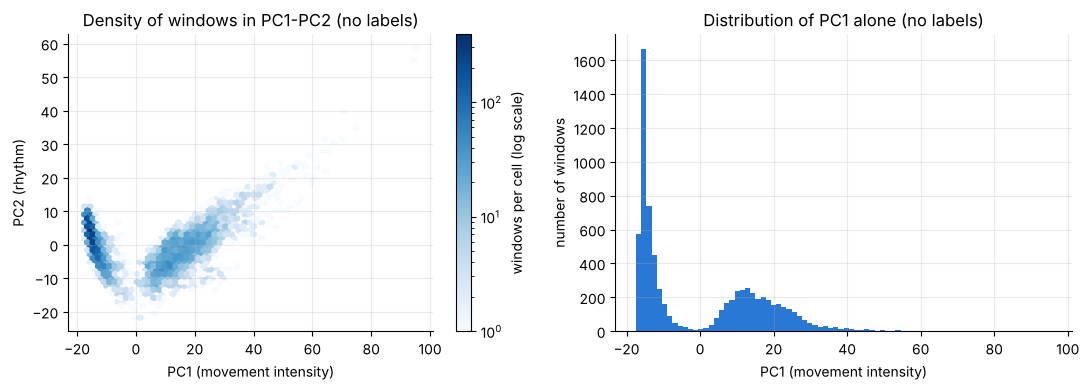

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hb = ax[0].hexbin(Z[:, 0], Z[:, 1], gridsize=60, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax[0], label="windows per cell (log scale)")
ax[0].set(title="Density of windows in PC1-PC2 (no labels)", xlabel="PC1 (movement intensity)", ylabel="PC2 (rhythm)")

ax[1].hist(Z[:, 0], bins=80, color="#2a78d6")
ax[1].set(title="Distribution of PC1 alone (no labels)", xlabel="PC1 (movement intensity)", ylabel="number of windows")
plt.tight_layout(); plt.show()

**Cluster tendency, measured: the Hopkins statistic**

Looking at a picture is subjective, so we also put a number on it. The **Hopkins statistic** compares two distances:
- how far a real window is from its nearest real neighbour, and
- how far a random fake point is from its nearest real window.

If the data are clumpy, real points sit close together while random points land in empty space, so the score gets close to **1**. A score near **0.5** means the data look like random noise with no structure.

In [12]:
def hopkins(data, n=500, seed=RNG):
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    real = data[rng.choice(len(data), n, replace=False)]
    w = nn.kneighbors(real)[0][:, 1]                            # real point -> nearest OTHER real point
    fake = rng.uniform(data.min(0), data.max(0), size=(n, data.shape[1]))
    u = nn.kneighbors(fake, n_neighbors=1)[0][:, 0]            # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

scores = [hopkins(Z[:, :10], seed=s) for s in range(5)]
print(f"Hopkins statistic on the first 10 PCs, 5 repeats: mean {np.mean(scores):.3f} (min {min(scores):.3f}, max {max(scores):.3f})")

Hopkins statistic on the first 10 PCs, 5 repeats: mean 0.941 (min 0.940, max 0.941)


**What this shows**
- The PC1 histogram has **two clear humps with a gap between them**. Even with no labels, the data naturally split into two big groups: windows with very little movement (left) and windows with a lot of movement (right).
- The right hump is **wide and flat**, while the left one is tall and narrow. The "moving" group is spread out, and the "still" group is packed tightly together.
- The Hopkins score is about **0.94**, far above the 0.5 of random data, so there is strong cluster tendency.

**A caution (good for the limitations box):** in many dimensions the Hopkins statistic is pushed upwards, because random points easily fall in empty space. So we treat it as *supporting* evidence, not proof. The two-hump histogram is the more convincing evidence.

#### 2.4 Now add the labels: which activity is where?

We colour the **same** points by their true activity. PCA did not use these colours; they only help us interpret the structure we already saw. We draw PC1 against PC2 and also PC1 against PC3, because PC3 was the posture axis.

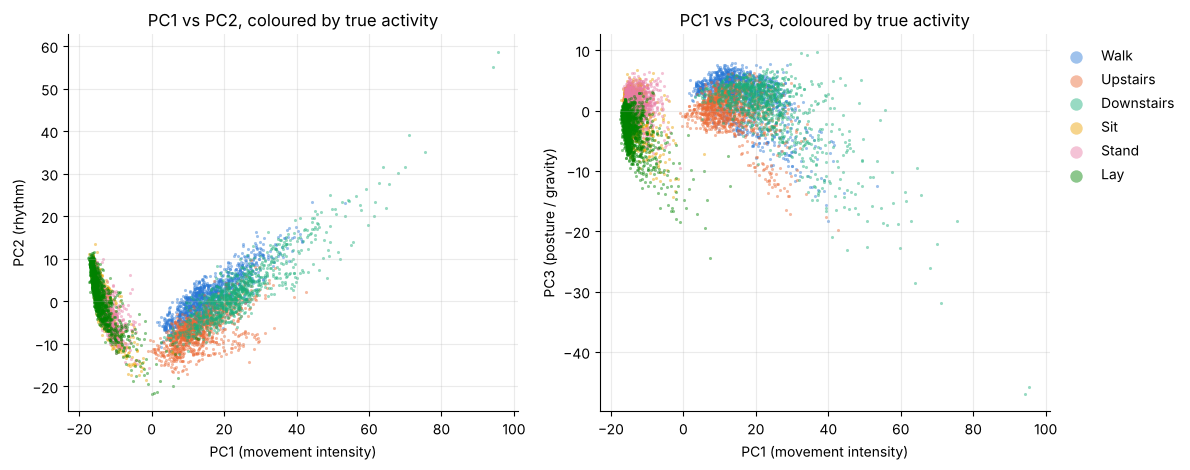

PC1        PC2       PC3     
                    mean   std mean  std mean  std
activity                                          
WALKING             15.8   7.4  1.0  4.9  2.3  3.8
WALKING_UPSTAIRS    12.9   6.5 -6.9  4.1 -0.2  3.4
WALKING_DOWNSTAIRS  23.8  10.9  2.1  7.3  0.1  5.7
SITTING            -14.0   2.5  1.0  5.3 -0.0  3.0
STANDING           -13.5   2.4  0.2  4.6  1.2  2.0
LAYING             -14.3   3.2  1.7  5.6 -3.1  3.2

In [13]:
def scatter_by_activity(ax, x, y, title, xl, yl, annotate=True):
    for a in ACT_ORDER:
        m = acts == a
        ax.scatter(x[m], y[m], s=5, alpha=0.45, color=COLORS[a], label=SHORT[a], linewidths=0)
        if annotate:
            ax.annotate(SHORT[a], (np.median(x[m]), np.median(y[m])), fontsize=9, weight="bold",
                        ha="center", color="#0b0b0b",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORS[a], alpha=0.9))
    ax.set(title=title, xlabel=xl, ylabel=yl)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
scatter_by_activity(ax[0], Z[:, 0], Z[:, 1], "PC1 vs PC2, coloured by true activity", "PC1 (movement intensity)", "PC2 (rhythm)", annotate=False)
scatter_by_activity(ax[1], Z[:, 0], Z[:, 2], "PC1 vs PC3, coloured by true activity", "PC1 (movement intensity)", "PC3 (posture / gravity)", annotate=False)
ax[1].legend(markerscale=4, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

summary = (pd.DataFrame({"activity": acts, "PC1": Z[:, 0], "PC2": Z[:, 1], "PC3": Z[:, 2]})
             .groupby("activity").agg(["mean", "std"]).round(1).reindex(ACT_ORDER))
summary

**What this shows**
- **The two humps from 2.3 are "moving" and "still".** Walking, upstairs and downstairs all sit on the right (high PC1). Sitting, standing and lying all sit on the left (low PC1).
- **In PC1-PC2, the three still activities sit almost on top of each other.** You cannot tell them apart in that view.
- **In PC1-PC3, lying shifts downwards (lower PC3) and starts to pull away from sitting and standing**, though it still touches them in this view. That makes sense physically: lying down turns the phone sideways, so gravity points in a different direction. Lying differs by **posture**, not by movement. We will see it separate much more clearly in 2.5.
- **Sitting and standing still overlap** in both views. Physically, both are upright and still. The only difference is a small change in body angle.
- The table shows that **walking downstairs has the biggest spread** on PC1 (std ≈ 11, compared with ≈ 2.5 for sitting). It is the most variable activity.

#### 2.5 Broad movement families, and finer groups inside each family

**Step 1: the broad split.** A very simple rule, PC1 > 0, splits the windows into two families. We check how well that rule matches "moving vs still".

In [14]:
is_dynamic = np.isin(acts, DYNAMIC)
family_pred = Z[:, 0] > 0
agree = (family_pred == is_dynamic).mean()
print(f"The simple rule 'PC1 > 0' puts {agree:.1%} of windows in the right family (moving vs still).")
print(pd.crosstab(pd.Series(np.where(is_dynamic, "moving (true)", "still (true)"), name=""),
                  pd.Series(np.where(family_pred, "PC1 > 0", "PC1 <= 0"), name="")))

The simple rule 'PC1 > 0' puts 99.8% of windows in the right family (moving vs still).
               PC1 <= 0  PC1 > 0
                                
moving (true)         3     3282
still (true)       4053       14


**Step 2: zoom inside each family.** We now run a *separate* PCA on each family. Inside one family, the big difference (moving vs still) is gone, so PCA can find the smaller differences that were hidden before.

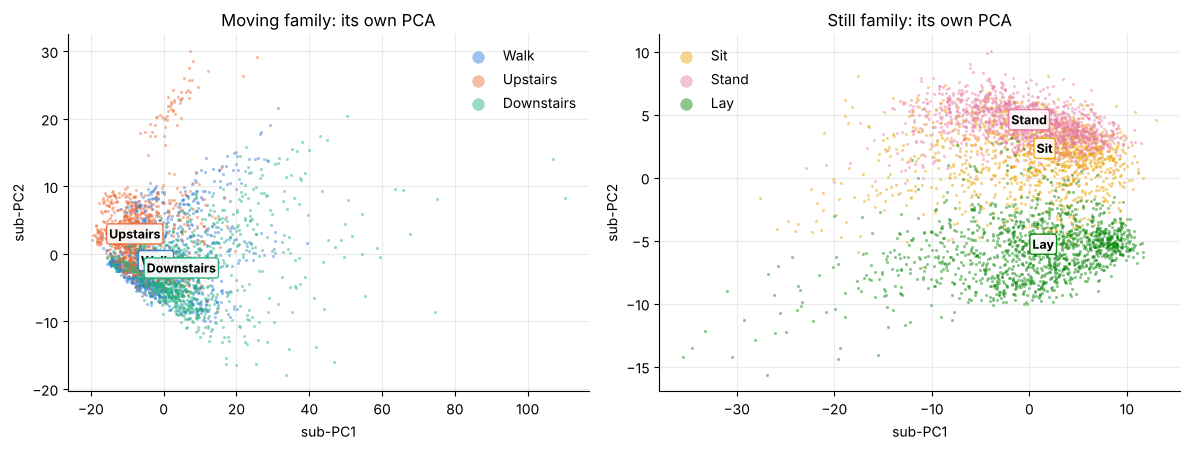

Moving family: first 3 sub-PCs hold [29.4  7.   5.6] % of the family's variance
Still family: first 3 sub-PCs hold [20.  11.   5.8] % of the family's variance


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sub_info = {}
for k, (name, members) in enumerate([("Moving family", DYNAMIC),
                                     ("Still family", ["SITTING", "STANDING", "LAYING"])]):
    m = np.isin(acts, members)
    p_sub = PCA(n_components=5, random_state=RNG).fit(X2[m])
    Zs = p_sub.transform(X2[m])
    sub_info[name] = np.round(p_sub.explained_variance_ratio_[:3] * 100, 1)
    for a in members:
        mm = acts[m] == a
        ax[k].scatter(Zs[mm, 0], Zs[mm, 1], s=5, alpha=0.45, color=COLORS[a], label=SHORT[a], linewidths=0)
        ax[k].annotate(SHORT[a], (np.median(Zs[mm, 0]), np.median(Zs[mm, 1])), fontsize=9, weight="bold",
                       ha="center", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORS[a], alpha=0.9))
    ax[k].set(title=f"{name}: its own PCA", xlabel="sub-PC1", ylabel="sub-PC2")
    ax[k].legend(markerscale=4, frameon=False)
plt.tight_layout(); plt.show()
for name, v in sub_info.items():
    print(f"{name}: first 3 sub-PCs hold {v} % of the family's variance")

**What this shows**
- **The broad split is almost perfect:** the rule `PC1 > 0` gets about **99.8%** of windows into the right family. "Moving vs still" is the strongest, most natural structure in the data.
- **Inside the still family:** **lying now forms its own clear region** (bottom of the plot). **Sitting and standing are still mixed**, although standing sits a little higher on average.
- **Inside the moving family:** **upstairs partly moves away** (to the left and up), but **walking and downstairs still overlap heavily** in this 2-D view. Downstairs also has a **long tail** of windows stretching far to the right, so its shape is stretched rather than round.
- The groups touch each other without clear gaps. That looks more like a **continuous** pattern with soft borders than like separate islands. *(Section 2.7 shows that walking and downstairs separate much better in the full space than in this 2-D view.)*

So the data look like a **hierarchy (a family tree)**, not six equal groups:

```
All windows
├── Moving:  walking, upstairs, downstairs   (close neighbours, soft borders, downstairs stretched)
└── Still:   lying  |  sitting + standing    (lying apart by posture; sitting and standing heavily mixed)
```

#### 2.6 Testing the family tree with distances

To check the tree with numbers, we compute the **centre** of each activity (its average position) in the first 50 PCs, then measure the distance between every pair of centres. A *dendrogram* joins the closest pair first, then the next closest, and so on.

We use 50 PCs because they keep about 87% of the information while removing much of the noise.

The first 50 PCs keep 87.5% of the information.


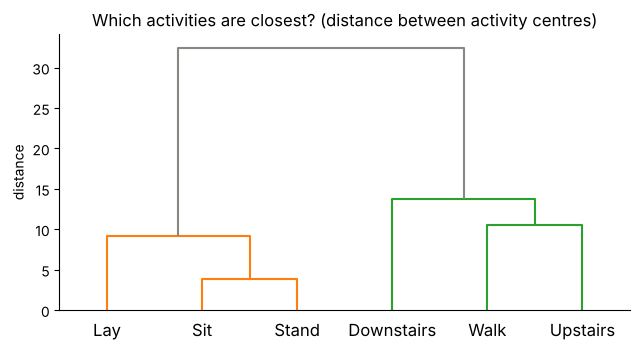

,Walk,Upstairs,Downstairs,Sit,Stand,Lay
Walk,0.0,10.6,11.9,30.4,30.0,31.3
Upstairs,10.6,0.0,15.6,28.4,28.0,29.4
Downstairs,11.9,15.6,0.0,38.2,37.9,38.7
Sit,30.4,28.4,38.2,0.0,3.9,8.2
Stand,30.0,28.0,37.9,3.9,0.0,10.2
Lay,31.3,29.4,38.7,8.2,10.2,0.0


In [16]:
N_PC = 50
Z50 = Z[:, :N_PC]
print(f"The first {N_PC} PCs keep {cum[N_PC-1]:.1%} of the information.")

centres = pd.DataFrame(Z50).groupby(acts).mean().reindex(ACT_ORDER)
dist = pd.DataFrame(squareform(pdist(centres)), index=[SHORT[a] for a in ACT_ORDER],
                    columns=[SHORT[a] for a in ACT_ORDER]).round(1)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
dendrogram(linkage(centres.values, method="average"), labels=[SHORT[a] for a in ACT_ORDER],
           ax=ax, color_threshold=20, above_threshold_color="#898781")
ax.set(title="Which activities are closest? (distance between activity centres)", ylabel="distance")
ax.grid(False); plt.tight_layout(); plt.show()
dist

**What this shows (read the dendrogram from the bottom up)**
1. **Sitting and standing join first** (distance ≈ 4). They are the most similar pair by far.
2. **Lying joins them next** (≈ 8–10): it is still close, but a little apart.
3. **Walking and upstairs join** (≈ 11), then **downstairs** joins them (≈ 12–16).
4. **The two families join only at the very top** (≈ 28–39), which is **about 2.5 to 10 times larger** than the distances inside a family.

This confirms the tree from 2.5 with numbers. It also answers one of RQ1's sub-questions: **yes, walking and upstairs are closer to each other than to downstairs, and sitting and standing are the closest pair of all.**

*Note:* these are distances between **centres**. They tell us how far apart groups are on average, but not how much the groups overlap. We measure overlap next.

#### 2.7 Measuring overlap: who are each window's neighbours?

**The idea:** for every window, find its **10 nearest neighbours** in the 50-PC space. If an activity is a clean, separate group, its windows' neighbours will almost all have the same activity. If two activities overlap, their neighbours will be mixed.

> *Real-life example:* if you live in a "Bangladeshi area" of a city, most of your 10 nearest neighbours are Bangladeshi. In a mixed area, your neighbours come from many backgrounds.

Each row of the table below answers: *"For windows of this activity, what share of their neighbours belong to each activity?"*

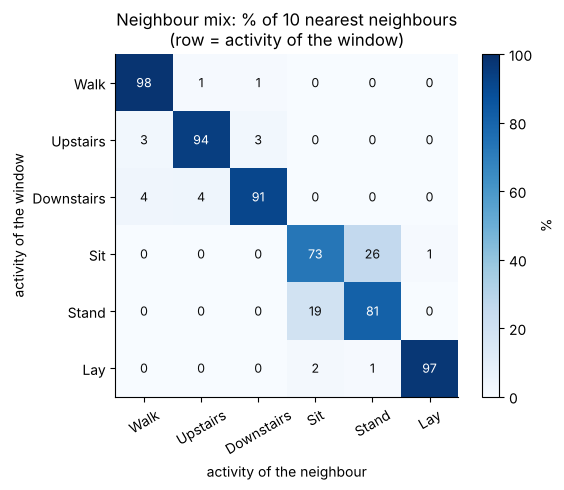

Same-activity neighbours using only PC1-PC2: 50.6%
Same-activity neighbours using 50 PCs:       88.8%


,Walk,Upstairs,Downstairs,Sit,Stand,Lay
Walk,98.4,0.8,0.8,0.0,0.0,0.0
Upstairs,3.0,94.2,2.8,0.0,0.0,0.0
Downstairs,4.3,4.5,91.2,0.0,0.0,0.0
Sit,0.0,0.1,0.0,72.9,25.9,1.1
Stand,0.0,0.0,0.0,19.1,80.9,0.1
Lay,0.0,0.1,0.0,1.8,1.0,97.1


In [17]:
K = 10
nn = NearestNeighbors(n_neighbors=K + 1).fit(Z50)
_, idx = nn.kneighbors(Z50)
nbr_acts = acts[idx[:, 1:]]                        # drop column 0 = the window itself

mix = pd.DataFrame({b: [(nbr_acts[acts == a] == b).mean() * 100 for a in ACT_ORDER] for b in ACT_ORDER},
                   index=ACT_ORDER)
mix.index = mix.columns = [SHORT[a] for a in ACT_ORDER]

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(mix.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(6), mix.columns, rotation=30); ax.set_yticks(range(6), mix.index)
for r in range(6):
    for c in range(6):
        v = mix.values[r, c]
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > 55 else "#0b0b0b")
ax.set(title="Neighbour mix: % of 10 nearest neighbours\n(row = activity of the window)",
       xlabel="activity of the neighbour", ylabel="activity of the window")
ax.grid(False); fig.colorbar(im, ax=ax, label="%"); plt.tight_layout(); plt.show()

# Does the 2-D picture tell the truth? Compare "same-activity neighbours" in 2 PCs vs 50 PCs
def purity(data):
    _, ix = NearestNeighbors(n_neighbors=K + 1).fit(data).kneighbors(data)
    return (acts[ix[:, 1:]] == acts[:, None]).mean()
print(f"Same-activity neighbours using only PC1-PC2: {purity(Z[:, :2]):.1%}")
print(f"Same-activity neighbours using 50 PCs:       {purity(Z50):.1%}")
mix.round(1)

**What this shows**
- **Walking (98%), lying (97%), upstairs (94%) and downstairs (91%) are well separated.** Most of their neighbours are the same activity.
- **Sitting and standing truly overlap.** About **26%** of a sitting window's neighbours are standing windows, and about **19%** the other way round. That is the only big overlap.
- **The moving activities overlap a little, with each other only** (3–5% for upstairs and downstairs). Moving and still windows are almost never neighbours (≈ 0%).
- **The 2-D picture is misleading.** With only PC1-PC2, only about **51%** of neighbours share the same activity. With 50 PCs, it is about **89%**. Many groups that look mixed in the flat 2-D plot are actually separate in the full space, the way two people can look close together in a photo while one stands far behind the other.

**Lesson for the poster:** a PCA scatter plot is useful for a first look, but conclusions about overlap must come from the full space, not the 2-D picture.

#### 2.8 Nested regions: how spread out is each activity, and are there groups inside groups?

Two checks:
1. **Spread (dispersion):** the average distance from each window to its activity's centre. A big number means the activity is loose and varied.
2. **People inside activities:** do a window's neighbours tend to come from the **same person**? If yes, each activity contains smaller "personal" sub-regions nested inside it. That would be a structure *finer* than the six labels.

If people did not matter, about 4.8% of neighbours would be from the same person (1 out of 21).
Observed over all windows: 53.7%


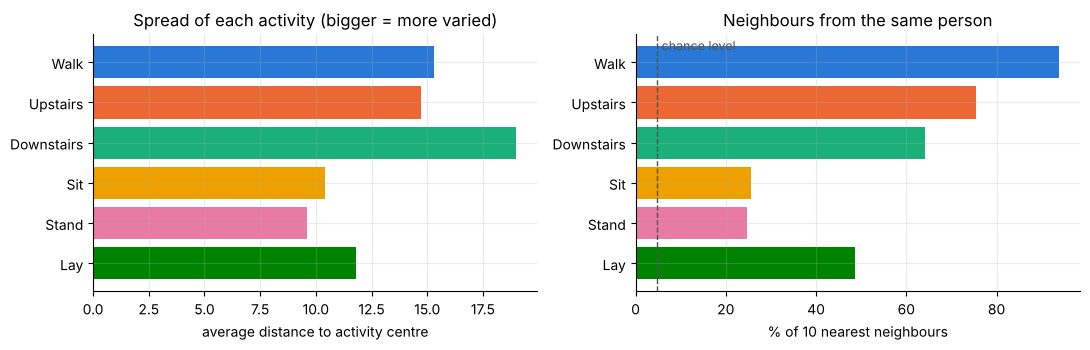

,windows,avg distance to centre (spread),% neighbours from SAME person
activity,,,
Walk,1226,15.3,93.8
Upstairs,1073,14.7,75.4
Downstairs,986,19.0,64.2
Sit,1286,10.4,25.6
Stand,1374,9.6,24.8
Lay,1407,11.8,48.7


In [18]:
rows = []
for a in ACT_ORDER:
    m = acts == a
    d = np.linalg.norm(Z50[m] - Z50[m].mean(0), axis=1)
    same_person = (subj[idx[m, 1:]] == subj[m, None]).mean()
    rows.append({"activity": SHORT[a], "windows": m.sum(),
                 "avg distance to centre (spread)": round(d.mean(), 1),
                 "% neighbours from SAME person": round(same_person * 100, 1)})
nested = pd.DataFrame(rows).set_index("activity")
chance = 100 / len(np.unique(subj))
overall = (subj[idx[:, 1:]] == subj[:, None]).mean() * 100
print(f"If people did not matter, about {chance:.1f}% of neighbours would be from the same person (1 out of 21).")
print(f"Observed over all windows: {overall:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh(nested.index[::-1], nested.iloc[::-1, 1], color=[COLORS[a] for a in ACT_ORDER[::-1]])
ax[0].set(title="Spread of each activity (bigger = more varied)", xlabel="average distance to activity centre")
ax[1].barh(nested.index[::-1], nested.iloc[::-1, 2], color=[COLORS[a] for a in ACT_ORDER[::-1]])
ax[1].axvline(chance, ls="--", color="#52514e", lw=1)
ax[1].text(chance + 1, 5.3, "chance level", color="#52514e", fontsize=9)
ax[1].set(title="Neighbours from the same person", xlabel="% of 10 nearest neighbours")
plt.tight_layout(); plt.show()
nested

**What this shows**
- **Downstairs is the most spread-out activity** (≈ 19), then walking and upstairs (≈ 15). The still activities are tight (≈ 10–12). So the moving activities are the most varied, and downstairs most of all. This connects to **Task 4**, which asks why downstairs shows up so often among unusual windows: an activity that is naturally spread out will have more points far from its centre.
- **People matter a lot, especially when moving.** If people did not matter, only about **5%** of neighbours would come from the same person. The real numbers are far higher:
  - **walking ≈ 94%**, upstairs ≈ 75%, downstairs ≈ 64%: each person's walk is almost like a **fingerprint** (this is called *gait*, the personal style of walking);
  - lying ≈ 49%, sitting and standing ≈ 25%: smaller, but still about **5 times** what chance would give.
- So inside each activity there are smaller **personal sub-regions**, and they are strongest for walking.
- This is a **nested** structure: *family → activity → person*. Part of it is natural (people really move differently). Part of it may come from the data collection: windows from one recording session overlap by 50% in time, so neighbouring windows are near-copies of each other. Both explanations should be kept in mind. **Task 5** looks at the person effect in detail.

#### 2.9 A second view: does a non-linear method agree? (t-SNE)

PCA can only rotate and flatten the data with straight lines. Groups that curve around each other may be hidden in a PCA plot. **t-SNE** is a non-linear method that tries to keep each point's neighbours close in a 2-D map. It is good at showing local groups.

**Two warnings about t-SNE:**
- Distances *between* far-apart groups and the *size* of groups in a t-SNE map are **not meaningful**. Only "who is next to whom" is meaningful.
- It is for looking only. We never cluster on a t-SNE map.

To keep it fast and less noisy, we run t-SNE on the first 50 PCs. This takes about a minute.

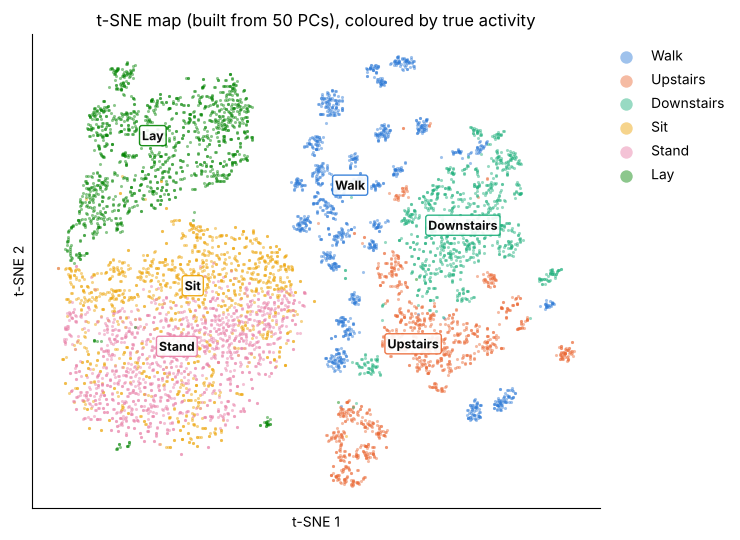

In [19]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RNG)
T = tsne.fit_transform(Z50)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
scatter_by_activity(ax, T[:, 0], T[:, 1], "t-SNE map (built from 50 PCs), coloured by true activity", "t-SNE 1", "t-SNE 2")
ax.legend(markerscale=4, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**What this shows**
- t-SNE tells the **same story** as PCA and the neighbour analysis, which makes us more confident:
  - moving and still windows form two separate areas;
  - lying forms its own clear island;
  - walking, upstairs and downstairs form neighbouring islands that touch;
  - sitting and standing are still partly mixed.
- **Walking breaks into many small, tight islands.** This fits the 94% same-person result in 2.8: each island is most likely one person's walking. That is structure **finer than the six labels**. Upstairs also shows a few islands; downstairs is a looser cloud.
- **Sitting and standing form one big shared area.** This is the same overlap found in 2.7.
- Lying sits next to them but mostly in its own area.

Because two very different methods (linear PCA and non-linear t-SNE) agree, the main structure is unlikely to be a side effect of one method.

#### 2.10 Summary of Task 2: evidence and hypotheses

**How the movement data are organised (evidence)**

| Finding | Evidence |
|---|---|
| The strongest structure is **moving vs still** | PC1 (intensity, ≈ 51% of variance) has two humps with a gap; `PC1 > 0` matches the families for 99.8% of windows; Hopkins ≈ 0.94 |
| The structure is a **hierarchy**, not six equal groups | Distances between families are about 2.5–10× larger than distances inside a family (dendrogram) |
| **Lying** is separated by **posture**, not movement | It separates from sitting and standing only along PC3 (gravity / orientation) |
| **Sitting and standing overlap** heavily | 19–26% of their neighbours are the other activity |
| **Walking, upstairs and downstairs** are neighbours with soft borders | 91–98% same-activity neighbours; small mixing only among themselves |
| **Downstairs** is the most varied activity | Largest spread on PC1 and in 50-PC space |
| Activities contain **person-specific sub-regions** | Same-person neighbours: walking ≈ 94%, still activities ≈ 25–49% (chance ≈ 5%); walking splits into many small t-SNE islands |
| A 2-D PCA plot **understates separation** | Same-activity neighbours: 51% in 2 PCs vs 89% in 50 PCs |

**Hypotheses to test with real clustering (RQ1) and anomaly detection (RQ2, RQ3)**
- **H1.** Clustering will find **2 groups (moving vs still) most clearly**. A choice of k = 2 may score better on internal measures such as silhouette than k = 6.
- **H2.** If we ask for 6 clusters, **sitting and standing will often be merged** or split in a way that does not follow the labels, while lying will form its own cluster.
- **H3.** Because the moving family is **long and spread out** instead of round, a method that allows stretched shapes (such as **GMM**) may fit it better than **K-means**, which assumes round groups of similar size.
- **H4.** Anomaly detectors will flag **more downstairs windows**, partly because downstairs is naturally more varied, not only because those windows are truly strange (link to Task 4 and RQ2).
- **H5.** Some "anomalies" may really be **person-specific movement styles**, especially for walking (link to Task 5 and RQ3). Clustering with many clusters may split walking **by person** instead of by activity.

**Limitations**
- Only the training set (21 people) was used. The test people may look slightly different.
- PCA finds straight-line structure only. t-SNE helps here, but t-SNE maps are not reliable for distances between groups.
- The features were pre-scaled to [-1, 1] by the dataset authors and then standardised again by us, so each feature has equal weight. Redundant features (Task 1) still give extra weight to the ideas they repeat.
- Windows overlap by 50% in time, so near neighbours can be near-copies. This may make the person effect and the cluster tendency look stronger than they really are.
- All the label comparisons above are **interpretation only**. Visual groupings are exploratory evidence, not validated clusters.


Task 3 — Physical interpretation of movement patterns
Objective: Understand which sensor characteristics distinguish or connect different movement patterns.

**Member**: Youssef

What needs to be done:
1. Explore acceleration, gyroscope and gravity-related feature distributions.
2. Compare time-domain and frequency-domain characteristics.
3. Identify which physical features differ most between activity groups.
4. Examine which activities share similar physical characteristics.
5. Investigate whether movement differences are associated with motion intensity, periodicity or orientation.
Expected output: Interpretable physical explanations for similarities and differences between movement patterns.



In [20]:
# Code for EDA 3

Task 4 — Movement variability and diversity
Objective: Determine whether some types of movement exhibit greater internal variation than others.

What needs to be done:
1. Compare within-activity feature variance and multivariate dispersion.
2. Examine local neighbourhood distances and density differences.
3. Investigate whether some activities contain several distinct movement patterns.
4. Determine whether activity variability is distributed across participants or concentrated in a few individuals.
5. Investigate why walking downstairs is disproportionately represented among the existing high-scoring unusual observations.
Expected output: Evidence identifying which movements are more heterogeneous and potential explanations for their apparent unusualness.

In [21]:
#subhashini

Task 5 — Participant-specific movement characteristics
Objective: Investigate whether individuals exhibit consistent and distinguishable movement patterns.

**Member**: Sushanth

What needs to be done:
1. Compare participants while controlling for activity type.
2. Examine how participant-specific feature distributions differ.
3. Investigate whether some participants occupy distinct regions within the same activity.
4. Compare within-participant and between-participant variability.
5. Examine whether participant 19 is consistently distinctive or whether only a few observations are extreme.
Expected output: Evidence showing whether individual movement differences are systematic or concentrated in isolated observations.


In [22]:
#sushanth

Task 6 — Preliminary anomaly characteristics and concentration
Objective: Investigate which observations appear unusual and whether they are isolated or associated with recurring patterns.

**Member**: Muhatasim

What needs to be done:
1. Reproduce baseline neighbourhood-distance anomaly scores.
2. Examine score distributions and identify high-scoring observations for inspection.
3. Analyse anomaly concentration across activities and participants, accounting for their different sample sizes.
4. Determine whether high-scoring observations have other similar unusual observations nearby.
5. Inspect selected raw inertial-signal windows to identify distinguishing signal characteristics.
6. Compare preliminary unusualness under global neighbourhoods and restricted neighbourhoods, without treating either as ground truth.
Expected output: A preliminary anomaly profile identifying the observations and patterns that warrant further investigation.

In [23]:
# eda part 6

## Research Questions

### Research Question 1
**Members**: Atharva & Abrar

**Main Research Question:** Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised movement patterns?

**Methodology:**
1.	Perform unsupervised clustering (e.g., K-Means, GMM) on the 561-feature space.
2.  Analyze the resulting cluster structures (evaluate whether they form distinct groups or hierarchical sub-clusters)
3.  Compare unsupervized cluster assignment directuly against the hierarchical sub-clusters)
4.  Analyze divergence between machine-discovered structures vs human labeled classes

**Sub-Questions & Focus:**

1. Are the clusters truly 6 distinct groups mirroring the activity labels?
2. Can a geometric hierarchy be discovered within the space (e.g., are walking flat and walking upstairs grouped closer together than sitting and standing)?
3. How clearly do static postures separate from dynamic movements?

In [24]:
# Code for Question 1

### Research Question 2
**Members**: Youssef & Sushanth

**Main Research Question:** Are some forms of human movement inherently more variable than others, and does this diversity explain why they appear disproportionately unusual?

**Methodology:**
1.	Execute anomaly detection models (e.g., Isolation Forest, density-based outlier scoring) across the feature space.
2.	Map anomaly and outlier scores directly back against cluster boundaries and feature variance metrics.
3.	Analyze whether anomaly concentrations are isolated to specific activities or driven by high-variance physical regimes.

**Questions and Focus:**
1. Are high-intensity or dynamic activities (like walking downstairs) inherently more variable, causing them to trigger false anomaly flags?
2. Are anomalies uniformly distributed across all activities, or clustered heavily in specific movement transitions?
3. Do unusual scores reflect true physical irregularities or geometric boundary crowding?


In [25]:
# Code for Question 2

### Research Question 3
**Members**: Muhatasim & Subhashini

**Main Research Question:** Do unusual movement observations represent consistent differences in how individuals move, or isolated departures from otherwise typical movement behaviour?

**Methodology:**
1.	Take the cluster assignments and anomaly shortlists generated in RQ1 and RQ2.
2.	Cross-tabulate these spatial outputs against the known subject ID metadata (the 30 participants).
3.	Evaluate whether outlier concentrations are driven by single individuals or shared across multiple subjects.
4.	Investigate how individual biometric walking styles interact with global unsupervised boundaries (leveraging the sequential nature of data per subject).

**Sub-questions and focus:**
1. Are the top anomalies dominated by a single eccentric participant (e.g., one subject's unique stride), or are they common instances experienced across many people?
2. Does the unsupervised space fracture by participant identity rather than activity class?
3. How does unmanaged inter-subject variance distort global anomaly detection?


In [26]:
# Code for Question 3